# Clustering Analysis on Microsoft GeoLife GPS Trajectory Dataset

## 1. Introduction

The objective of this project is to apply unsupervised machine learning techniques to the Microsoft GeoLife GPS Trajectory Dataset to identify geographical patterns in GPS observations.

The project implements K-Means clustering and Agglomerative Hierarchical Clustering and evaluates their performance using internal clustering metrics and visualizations.

In [1]:
# Step 1: Import libraries and check the dataset path

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Dataset location
csv_path = Path(
    r"C:\Users\Hruda\Downloads\ML_Project\geolife_trajectories.csv"
)

# Check whether the file exists
if csv_path.exists():
    print("Dataset found successfully!")
    print(f"File size: {csv_path.stat().st_size / (1024**3):.2f} GB")
else:
    print("Dataset not found. Please check the file path.")

Dataset found successfully!
File size: 1.57 GB


In [2]:
# Step 2: Load a representative sample efficiently

from pathlib import Path
import pandas as pd
import numpy as np

csv_path = Path(
    r"C:\Users\Hruda\Downloads\ML_Project\geolife_trajectories.csv"
)

required_columns = [
    "UserID",
    "TrajectoryID",
    "Latitude",
    "Longitude",
    "Altitude"
]

sample_size = 10_000
chunk_size = 100_000
random_seed = 42

if not csv_path.exists():
    raise FileNotFoundError(f"Dataset not found: {csv_path}")

rng = np.random.default_rng(random_seed)
sample_chunks = []
rows_read = 0

for chunk in pd.read_csv(
    csv_path,
    usecols=required_columns,
    dtype={
        "UserID": "int32",
        "TrajectoryID": "string",
        "Latitude": "float32",
        "Longitude": "float32",
        "Altitude": "float32"
    },
    chunksize=chunk_size
):
    rows_read += len(chunk)

    # Keep a random sample from this chunk
    take = min(sample_size, len(chunk))
    positions = rng.choice(len(chunk), size=take, replace=False)
    sample_chunks.append(chunk.iloc[positions])

    # Keep the sample size manageable after each chunk
    combined = pd.concat(sample_chunks, ignore_index=True)

    if len(combined) > sample_size:
        keep = rng.choice(
            len(combined),
            size=sample_size,
            replace=False
        )
        combined = combined.iloc[keep].reset_index(drop=True)

    sample_chunks = [combined]

sample_df = pd.concat(sample_chunks, ignore_index=True)

print("Sampling completed!")
print(f"Rows scanned: {rows_read:,}")
print(f"Rows in sample: {len(sample_df):,}")
print(f"Sample memory usage: {sample_df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

display(sample_df.head())

Sampling completed!
Rows scanned: 24,876,978
Rows in sample: 10,000
Sample memory usage: 0.75 MB


,UserID,TrajectoryID,Latitude,Longitude,Altitude
0,180,20090528211734,33.990021,115.787964,98.682106
1,168,20110728230752,30.129541,118.162666,5892.000000
2,174,20080702092548,39.977749,116.301750,262.467194
3,180,20090528211734,30.612200,114.959915,84.717003
4,179,20081101013523,39.991501,116.330879,295.000000


## 2. Dataset Description and Preprocessing

The Microsoft GeoLife GPS Trajectory Dataset contains geographical trajectory observations collected from GPS-enabled devices. The dataset includes latitude, longitude, altitude, and trajectory-related information.

Due to the size of the dataset, a sample was used for this analysis. The data was inspected and cleaned by handling missing or invalid coordinates and removing duplicate records based on the selected trajectory and location fields.

In [3]:
# Step 3: Explore the sampled dataset

print("Dataset shape:", sample_df.shape)

print("\nColumn information:")
sample_df.info()

print("\nFirst 5 rows:")
display(sample_df.head())

print("\nStatistical summary:")
display(sample_df.describe())

print("\nMissing values:")
display(sample_df.isnull().sum())

print("\nDuplicate rows:", sample_df.duplicated().sum())

Dataset shape: (10000, 5)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   UserID        10000 non-null  int32  
 1   TrajectoryID  10000 non-null  string 
 2   Latitude      10000 non-null  float32
 3   Longitude     10000 non-null  float32
 4   Altitude      10000 non-null  float32
dtypes: float32(3), int32(1), string(1)
memory usage: 234.5 KB

First 5 rows:


,UserID,TrajectoryID,Latitude,Longitude,Altitude
0,180,20090528211734,33.990021,115.787964,98.682106
1,168,20110728230752,30.129541,118.162666,5892.000000
2,174,20080702092548,39.977749,116.301750,262.467194
3,180,20090528211734,30.612200,114.959915,84.717003
4,179,20081101013523,39.991501,116.330879,295.000000



Statistical summary:


,UserID,Latitude,Longitude,Altitude
count,10000.000000,10000.000000,10000.000000,10000.000000
mean,177.422000,38.569801,105.463326,197.007431
std,4.044299,5.780549,49.400208,445.034973
min,167.000000,26.161274,-151.268143,-971.099976
25%,179.000000,35.735222,115.798050,91.146999
50%,179.000000,39.992386,116.307156,132.247040
75%,180.000000,40.051683,116.326160,191.000000
max,181.000000,62.999546,119.943230,12096.500000



Missing values:


UserID          0
TrajectoryID    0
Latitude        0
Longitude       0
Altitude        0
dtype: int64


Duplicate rows: 37


In [4]:
# Step 3.2: Clean and validate GPS records

clean_df = sample_df.copy()

rows_before = len(clean_df)

# Remove rows with missing GPS coordinates
clean_df = clean_df.dropna(subset=["Latitude", "Longitude"])

# Remove non-finite GPS coordinates
finite_coords = (
    np.isfinite(clean_df["Latitude"]) &
    np.isfinite(clean_df["Longitude"])
)
clean_df = clean_df.loc[finite_coords].copy()

# Keep only valid geographic coordinates
valid_coords = (
    clean_df["Latitude"].between(-90, 90) &
    clean_df["Longitude"].between(-180, 180)
)
clean_df = clean_df.loc[valid_coords].copy()

# Remove duplicate GPS records based on location and trajectory
clean_df = clean_df.drop_duplicates(
    subset=["UserID", "TrajectoryID", "Latitude", "Longitude"]
).reset_index(drop=True)

rows_after = len(clean_df)

print("Cleaning completed!")
print(f"Rows before cleaning: {rows_before:,}")
print(f"Rows after cleaning:  {rows_after:,}")
print(f"Rows removed:         {rows_before - rows_after:,}")

print("\nRemaining missing values:")
display(clean_df.isnull().sum())

display(clean_df.head())

Cleaning completed!
Rows before cleaning: 10,000
Rows after cleaning:  9,886
Rows removed:         114

Remaining missing values:


UserID          0
TrajectoryID    0
Latitude        0
Longitude       0
Altitude        0
dtype: int64

,UserID,TrajectoryID,Latitude,Longitude,Altitude
0,180,20090528211734,33.990021,115.787964,98.682106
1,168,20110728230752,30.129541,118.162666,5892.000000
2,174,20080702092548,39.977749,116.301750,262.467194
3,180,20090528211734,30.612200,114.959915,84.717003
4,179,20081101013523,39.991501,116.330879,295.000000


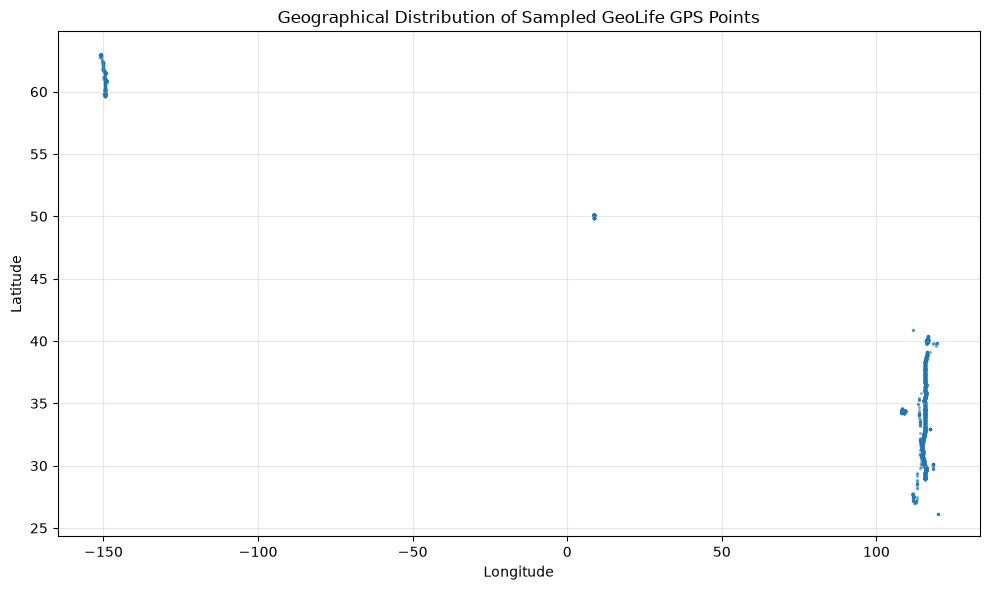

In [5]:
# Step 3.3: Visualize sampled GPS locations

plt.figure(figsize=(10, 6))

plt.scatter(
    clean_df["Longitude"],
    clean_df["Latitude"],
    s=2,
    alpha=0.4
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Distribution of Sampled GeoLife GPS Points")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Observations
- Each point represents a GPS location.
- X-axis shows longitude and Y-axis shows latitude.
- Dense areas contain more GPS observations.
- The graph shows the geographical distribution before clustering.

## 3. Feature Selection and Scaling

Latitude and longitude were selected as the primary features for clustering. User and trajectory identifiers were excluded because they represent identities rather than geographical measurements.

The selected features were standardized using `StandardScaler` before applying the clustering algorithms. This allows both features to contribute on a comparable scale.

In [6]:
# Step 4.1: Select GPS features for clustering

features = ["Latitude", "Longitude"]

X = clean_df[features].copy()

print("Selected features:", features)
print("Feature matrix shape:", X.shape)

display(X.head())

Selected features: ['Latitude', 'Longitude']
Feature matrix shape: (9886, 2)


,Latitude,Longitude
0,33.990021,115.787964
1,30.129541,118.162666
2,39.977749,116.301750
3,30.612200,114.959915
4,39.991501,116.330879


In [7]:
# Step 4.2: Standardize the selected features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled feature matrix shape:", X_scaled.shape)

print("\nScaled feature means:")
print(X_scaled.mean(axis=0).round(4))

print("\nScaled feature standard deviations:")
print(X_scaled.std(axis=0).round(4))

Scaled feature matrix shape: (9886, 2)

Scaled feature means:
[-0.  0.]

Scaled feature standard deviations:
[1. 1.]


## 4. K-Means Clustering

K-Means partitions observations into a predefined number of clusters by assigning each observation to its nearest cluster centroid.

### 4.1 Elbow Method

The Elbow method was used to examine the inertia for different values of k. Inertia measures the sum of squared distances between observations and their assigned cluster centroids. The curve was inspected to choose a reasonable number of clusters.

In [8]:
# Step 5.1: Elbow method for K-Means

inertias = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

print("Elbow method calculations completed.")

for k, inertia in zip(k_values, inertias):
    print(f"k = {k}, Inertia = {inertia:.2f}")

Elbow method calculations completed.
k = 2, Inertia = 5393.81
k = 3, Inertia = 1640.54
k = 4, Inertia = 535.09
k = 5, Inertia = 185.70
k = 6, Inertia = 101.51
k = 7, Inertia = 63.13
k = 8, Inertia = 49.07
k = 9, Inertia = 36.94
k = 10, Inertia = 30.08


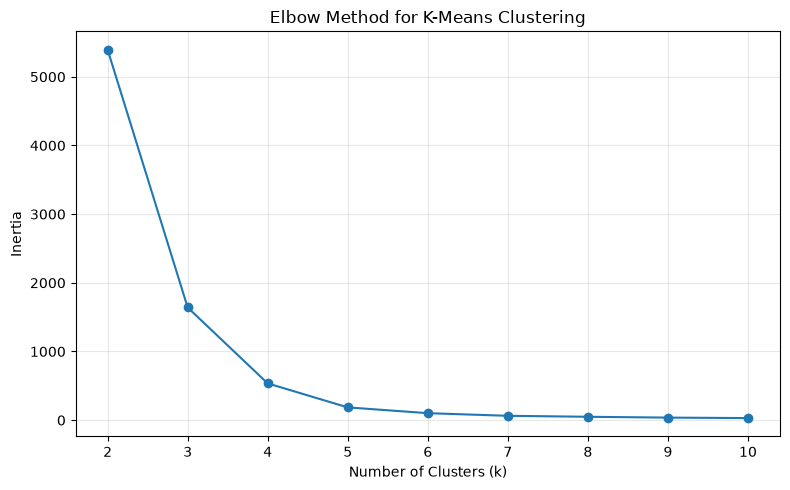

In [9]:
# Step 5.2: Plot the Elbow curve

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertias,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means Clustering")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Observations
- X-axis represents the number of clusters (K).
- Y-axis represents inertia.
- Inertia decreases as K increases.
- K = 5 was selected based on the elbow curve.

### 4.2 K-Means Evaluation and Visualization

The final K-Means model was fitted using five clusters. Its performance was evaluated using the Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index.

PCA was used to project the selected features into two dimensions for visual inspection of the cluster assignments.


In [10]:
# Step 5.3: Fit the final K-Means model

best_k = 5

kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X_scaled)

clean_df["KMeans_Cluster"] = kmeans_labels

print("K-Means model fitted successfully!")
print("Number of clusters:", best_k)
print("\nCluster sizes:")
print(clean_df["KMeans_Cluster"].value_counts().sort_index())

K-Means model fitted successfully!
Number of clusters: 5

Cluster sizes:
KMeans_Cluster
0    1461
1    6600
2     338
3     143
4    1344
Name: count, dtype: int64


In [11]:
# Step 5.4: Evaluate K-Means clustering

silhouette = silhouette_score(X_scaled, kmeans_labels)
db_index = davies_bouldin_score(X_scaled, kmeans_labels)
ch_index = calinski_harabasz_score(X_scaled, kmeans_labels)

print(f"Silhouette Score:           {silhouette:.4f}")
print(f"Davies-Bouldin Index:       {db_index:.4f}")
print(f"Calinski-Harabasz Index:    {ch_index:.4f}")

Silhouette Score:           0.8480
Davies-Bouldin Index:       0.2660
Calinski-Harabasz Index:    260563.4840


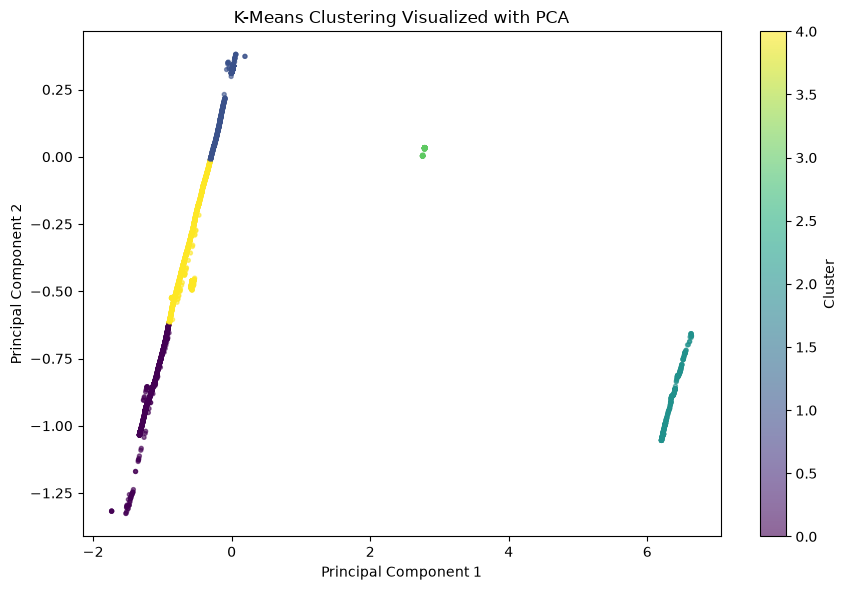

Variance explained by the two PCA components: 100.00%


In [12]:
# Step 5.5: PCA visualization of K-Means clusters

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=8,
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering Visualized with PCA")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

print(
    "Variance explained by the two PCA components:",
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

### Observations
- Different colors represent different clusters.
- PCA reduces the features to two dimensions for visualization.
- The graph shows how K-Means groups the GPS observations.

## 5. Agglomerative Hierarchical Clustering

Agglomerative Hierarchical Clustering begins with individual observations and progressively merges them into larger clusters.

### 5.1 Linkage Strategy Comparison

Ward, complete, and average linkage strategies were compared using five clusters. Their Silhouette Scores, Davies-Bouldin Indices, and Calinski-Harabasz Indices were calculated to examine differences in clustering quality.

### 5.2 Dendrogram

A dendrogram was generated using Ward linkage to visualize the hierarchical merging process. A smaller subset was used to keep the visualization computationally manageable.

In [13]:
# Step 6.1: Prepare a subset for hierarchical clustering

hier_sample_size = min(2000, len(X_scaled))

rng = np.random.default_rng(42)
hier_indices = np.sort(
    rng.choice(len(X_scaled), size=hier_sample_size, replace=False)
)

X_hier = X_scaled[hier_indices]

print("Hierarchical clustering sample size:", len(X_hier))
print("Number of features:", X_hier.shape[1])

Hierarchical clustering sample size: 2000
Number of features: 2


In [14]:
# Step 6.2: Compare Agglomerative Clustering linkage strategies

linkage_results = []

for linkage_method in ["ward", "complete", "average"]:
    model = AgglomerativeClustering(
        n_clusters=5,
        linkage=linkage_method
    )

    labels = model.fit_predict(X_hier)

    silhouette = silhouette_score(X_hier, labels)
    db_index = davies_bouldin_score(X_hier, labels)
    ch_index = calinski_harabasz_score(X_hier, labels)

    linkage_results.append({
        "Linkage": linkage_method,
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": db_index,
        "Calinski-Harabasz Index": ch_index
    })

linkage_df = pd.DataFrame(linkage_results)

display(linkage_df.round(4))

,Linkage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,ward,0.8189,0.2876,28909.8428
1,complete,0.8312,0.2779,42679.6796
2,average,0.8192,0.2664,42582.5137


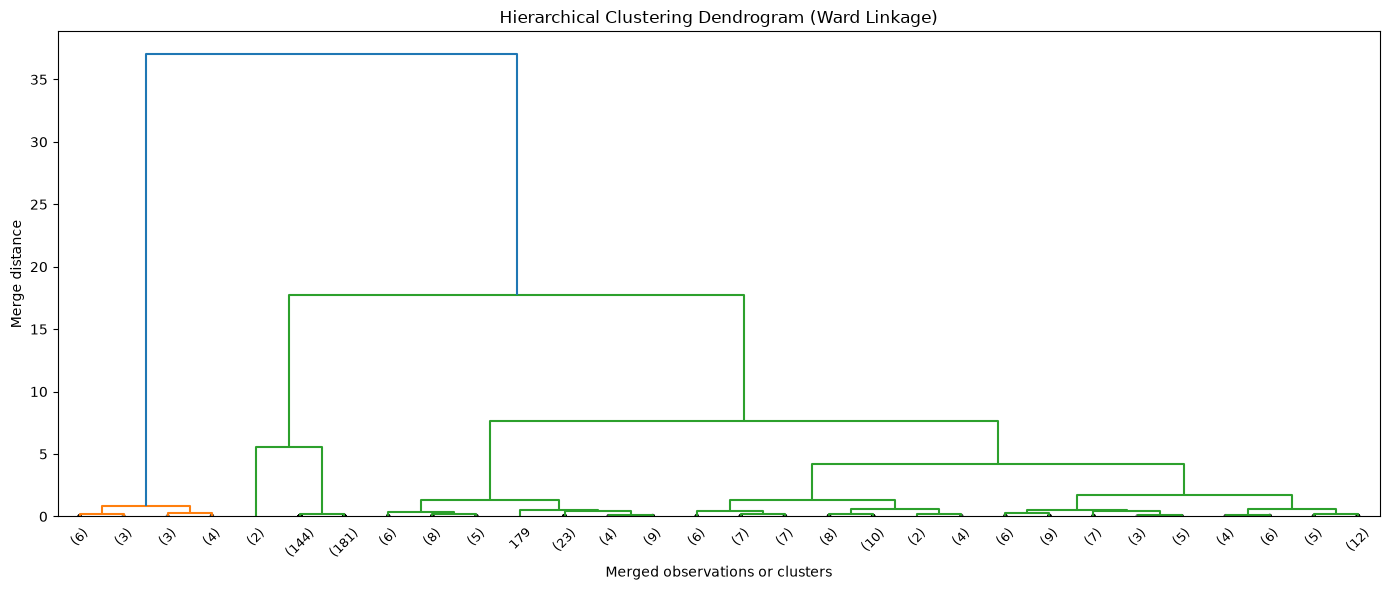

In [15]:
# Step 6.3: Generate a dendrogram

from scipy.cluster.hierarchy import dendrogram, linkage

# Use a smaller subset to keep the dendrogram readable
dendrogram_size = min(500, len(X_hier))
X_dendrogram = X_hier[:dendrogram_size]

Z = linkage(X_dendrogram, method="ward", metric="euclidean")

plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=45,
    leaf_font_size=9,
    show_contracted=True
)

plt.title("Hierarchical Clustering Dendrogram (Ward Linkage)")
plt.xlabel("Merged observations or clusters")
plt.ylabel("Merge distance")
plt.tight_layout()
plt.show()

### Observations
- The dendrogram shows how clusters are merged.
- The Y-axis represents the merging distance.
- Large vertical gaps can indicate distinct groups.

### 5.3 Final Agglomerative Model and PCA Visualization

Average linkage was selected for the final Agglomerative model because it achieved the lowest Davies-Bouldin Index in the initial linkage comparison.

The model was fitted using five clusters. PCA was used to visualize the resulting cluster assignments in two dimensions.

In [16]:
# Step 6.4: Fit final Agglomerative Clustering model

final_linkage = "average"
final_k = 5

agg_model = AgglomerativeClustering(
    n_clusters=final_k,
    linkage=final_linkage
)

agg_labels = agg_model.fit_predict(X_hier)

print("Agglomerative Clustering completed!")
print("Linkage method:", final_linkage)
print("Number of clusters:", final_k)

print("\nCluster sizes:")
display(
    pd.Series(agg_labels, name="Cluster")
    .value_counts()
    .sort_index()
)

Agglomerative Clustering completed!
Linkage method: average
Number of clusters: 5

Cluster sizes:


Cluster
0     367
1    1348
2      24
3      69
4     192
Name: count, dtype: int64

In [17]:
# Step 6.5: Evaluate Agglomerative Clustering

agg_silhouette = silhouette_score(X_hier, agg_labels)
agg_db_index = davies_bouldin_score(X_hier, agg_labels)
agg_ch_index = calinski_harabasz_score(X_hier, agg_labels)

print(f"Silhouette Score:        {agg_silhouette:.4f}")
print(f"Davies-Bouldin Index:    {agg_db_index:.4f}")
print(f"Calinski-Harabasz Index: {agg_ch_index:.4f}")

Silhouette Score:        0.8192
Davies-Bouldin Index:    0.2664
Calinski-Harabasz Index: 42582.5137


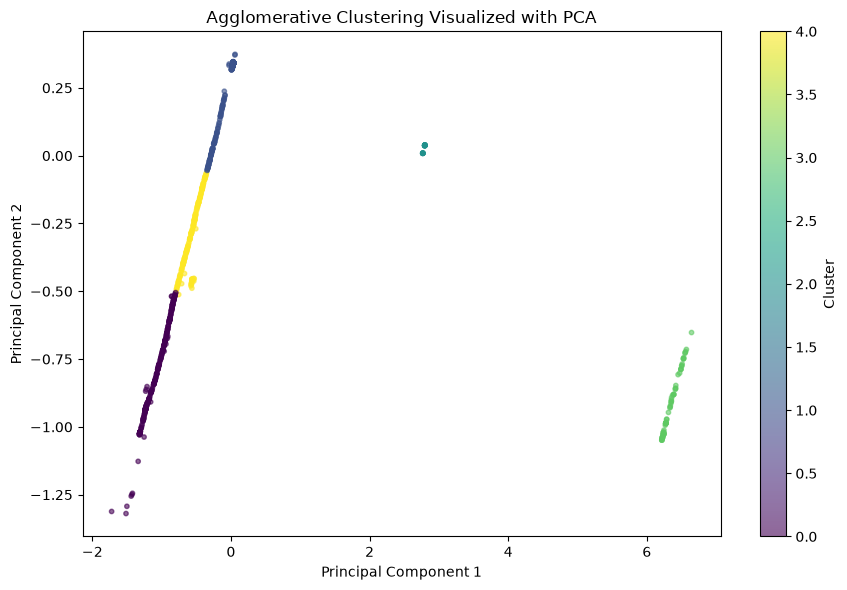

Variance explained by two PCA components: 100.00%


In [18]:
# Step 6.6: PCA visualization of Agglomerative Clustering

pca_agg = PCA(n_components=2)
X_hier_pca = pca_agg.fit_transform(X_hier)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_hier_pca[:, 0],
    X_hier_pca[:, 1],
    c=agg_labels,
    cmap="viridis",
    s=10,
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Agglomerative Clustering Visualized with PCA")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

print(
    "Variance explained by two PCA components:",
    f"{pca_agg.explained_variance_ratio_.sum():.2%}"
)

### Observations
- Different colors represent Agglomerative clusters.
- PCA helps visualize the clustering results in two dimensions.
- The graph helps inspect cluster separation and overlap.

## 6. t-SNE Visualization

t-distributed Stochastic Neighbor Embedding (t-SNE) was used to visualize a subset of the K-Means cluster assignments in two dimensions. It helps inspect local patterns in high-dimensional representations, although the axes do not correspond directly to latitude and longitude.

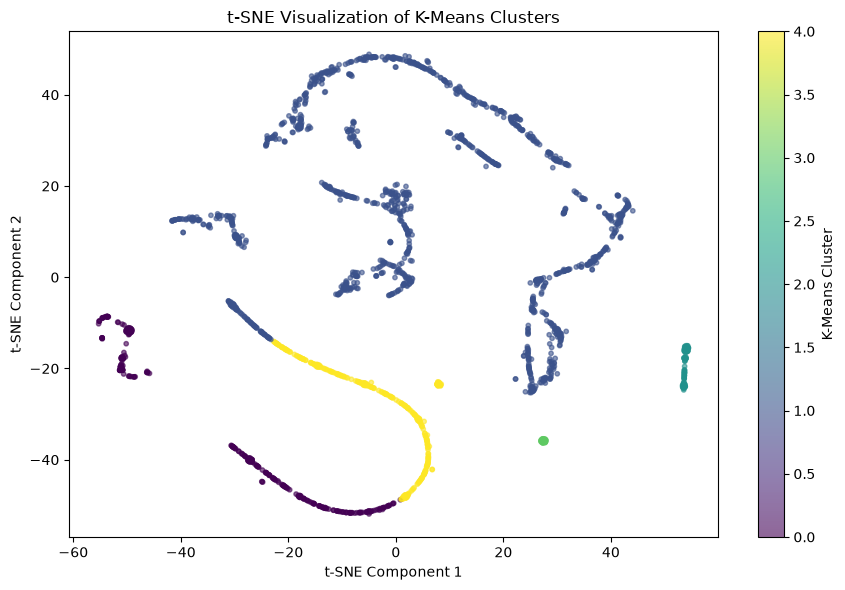

t-SNE completed successfully.
Number of observations visualized: 2000


In [19]:
# Step 7: t-SNE visualization of K-Means clusters

tsne_size = min(2000, len(X_scaled))

rng = np.random.default_rng(42)
tsne_indices = np.sort(
    rng.choice(len(X_scaled), size=tsne_size, replace=False)
)

X_tsne_input = X_scaled[tsne_indices]
tsne_labels = kmeans_labels[tsne_indices]

tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=42
)

X_tsne = tsne.fit_transform(X_tsne_input)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=tsne_labels,
    cmap="viridis",
    s=10,
    alpha=0.6
)

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("t-SNE Visualization of K-Means Clusters")
plt.colorbar(scatter, label="K-Means Cluster")
plt.tight_layout()
plt.show()

print("t-SNE completed successfully.")
print("Number of observations visualized:", len(X_tsne))

### Observations
- Each point represents a GPS observation.
- Colors represent K-Means cluster assignments.
- t-SNE helps visualize local patterns in two dimensions.

## 7. Final Algorithm Comparison

K-Means and Agglomerative Hierarchical Clustering were evaluated on the same sample of 2,000 observations, with five clusters for each model. Using the same observations makes the internal metric comparison more meaningful.

The Silhouette Score and Calinski-Harabasz Index are generally better when higher, while the Davies-Bouldin Index is generally better when lower. All three metrics were considered when interpreting the results.

In [20]:
# Step 8.1: Compare both algorithms on the same 2,000 observations

# K-Means on the shared sample
kmeans_compare = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)
kmeans_compare_labels = kmeans_compare.fit_predict(X_hier)

# Agglomerative clustering on the same sample
agg_compare = AgglomerativeClustering(
    n_clusters=5,
    linkage="average"
)
agg_compare_labels = agg_compare.fit_predict(X_hier)

print("Both models fitted on the same observations.")
print("Shared sample size:", len(X_hier))

Both models fitted on the same observations.
Shared sample size: 2000


In [21]:
# Step 8.2: Final comparison using the same observations

def calculate_metrics(X_data, labels):
    return {
        "Silhouette Score": silhouette_score(X_data, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_data, labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(
            X_data, labels
        )
    }

comparison_df = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        "Clusters": 5,
        **calculate_metrics(X_hier, kmeans_compare_labels)
    },
    {
        "Algorithm": "Agglomerative (Average)",
        "Clusters": 5,
        **calculate_metrics(X_hier, agg_compare_labels)
    }
])

display(comparison_df.round(4))

,Algorithm,Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,5,0.8392,0.2798,48394.8425
1,Agglomerative (Average),5,0.8192,0.2664,42582.5137


### Observations
- The graph compares the clustering algorithms using the Davies-Bouldin Index.
- Lower values indicate better clustering performance.
- K-Means scored 0.2798.
- Agglomerative clustering scored 0.2664.
- Agglomerative clustering performed better on this metric.

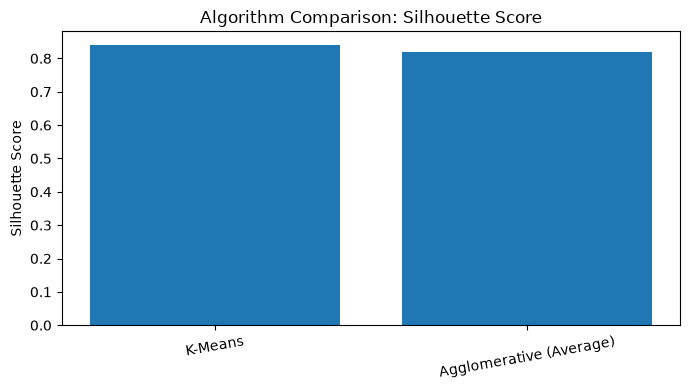

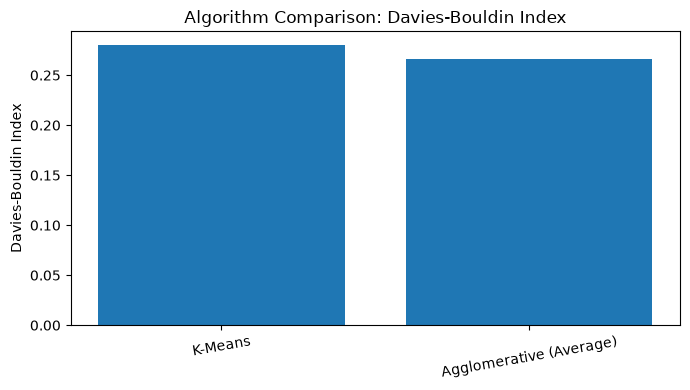

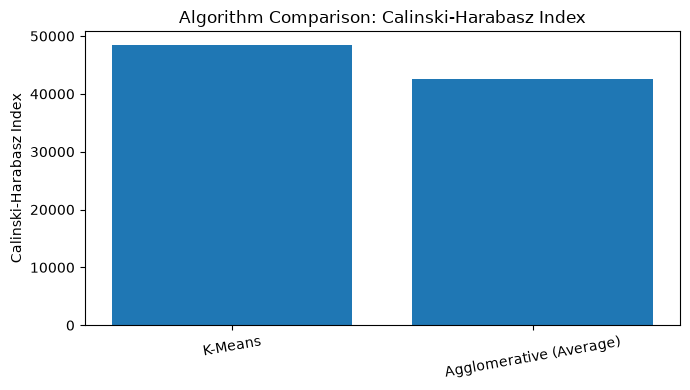

In [22]:
# Step 8.3: Compare metric values visually

metrics_to_plot = [
    "Silhouette Score",
    "Davies-Bouldin Index",
    "Calinski-Harabasz Index"
]

for metric in metrics_to_plot:
    plt.figure(figsize=(7, 4))

    plt.bar(
        comparison_df["Algorithm"],
        comparison_df[metric]
    )

    plt.title(f"Algorithm Comparison: {metric}")
    plt.ylabel(metric)
    plt.xticks(rotation=10)
    plt.tight_layout()
    plt.show()

## 9. Results and Discussion

### K-Means Clustering

K-Means was applied to the GeoLife GPS dataset using latitude and longitude as features. The Elbow method was used to select five clusters. The model achieved a Silhouette Score of 0.8480, a Davies-Bouldin Index of 0.2660, and a Calinski-Harabasz Index of 260563.4840 on the full cleaned sample.

### Agglomerative Hierarchical Clustering

Agglomerative clustering was evaluated using Ward, complete, and average linkage strategies. Average linkage produced a Davies-Bouldin Index of 0.2664 in the linkage comparison. A dendrogram was generated using Ward linkage to examine the hierarchical merging of observations.

### Comparison of Algorithms

On the same 2,000 observations, K-Means achieved a Silhouette Score of 0.8392 and a Calinski-Harabasz Index of 48394.8425. Agglomerative clustering with average linkage achieved a Silhouette Score of 0.8192 and a Calinski-Harabasz Index of 42582.5137. Agglomerative clustering had the lower Davies-Bouldin Index, at 0.2664, compared with 0.2798 for K-Means.

These results indicate that K-Means performed better on two of the three evaluation metrics, while Agglomerative clustering performed better on the Davies-Bouldin Index. The comparison demonstrates that different internal metrics can favor different clustering methods.

### Visualization Findings

The PCA plots show the cluster assignments in two dimensions. The t-SNE visualization provides another view of the K-Means clusters. These plots help explore spatial patterns, but they do not establish that the clusters correspond to specific transportation modes or activities.

### Limitations

The analysis uses a representative sample rather than the entire dataset because of the dataset's size and computational cost. The clustering features are limited to latitude and longitude, and the resulting clusters reflect approximate geographic proximity. The number of clusters and the sampling strategy can influence the results.

## 10. Conclusion

This project applied K-Means and Agglomerative Hierarchical Clustering to the Microsoft GeoLife GPS Trajectory Dataset. The Elbow method supported selecting five clusters for K-Means, while hierarchical clustering was examined using multiple linkage strategies and a dendrogram.

Both algorithms were evaluated using Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index. On a shared sample of 2,000 observations, K-Means performed better on the Silhouette and Calinski-Harabasz metrics, while Agglomerative clustering achieved a lower Davies-Bouldin Index.

PCA and t-SNE visualizations were used to inspect the cluster assignments. Overall, the project demonstrates how unsupervised learning can explore geographic patterns in GPS data. The findings should be interpreted in light of the sampling strategy, selected features, and limitations of internal clustering metrics.